In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from sklearn.ensemble import RandomForestRegressor

import joblib

In [2]:
train = pd.read_csv(
    "../data/train.csv"
)

test = pd.read_csv(
    "../data/test.csv"
)

In [3]:
print(train.shape)
print(test.shape)

(913000, 4)
(45000, 4)


In [4]:
train.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [6]:
train["date"] = pd.to_datetime(
    train["date"]
)

test["date"] = pd.to_datetime(
    test["date"]
)

In [7]:
train["date"] = pd.to_datetime(
    train["date"]
)

test["date"] = pd.to_datetime(
    test["date"]
)

In [8]:
train = train.sort_values(
    [
        "store",
        "item",
        "date"
    ]
)

In [9]:
train = train.sort_values(
    [
        "store",
        "item",
        "date"
    ]
)

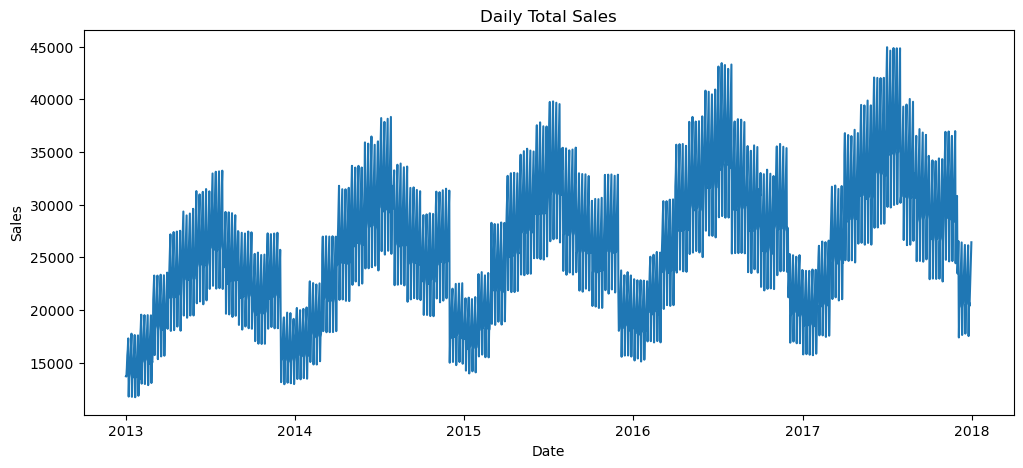

In [10]:
daily_sales = train.groupby(
    "date"
)["sales"].sum()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_sales
)

plt.title(
    "Daily Total Sales"
)

plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()

In [11]:
train["year"] = train["date"].dt.year

train["month"] = train["date"].dt.month

train["day"] = train["date"].dt.day

train["day_of_week"] = (
    train["date"].dt.dayofweek
)

train["week_of_year"] = (
    train["date"].dt.isocalendar().week.astype(int)
)

In [12]:
train["lag_1"] = train.groupby(
    ["store", "item"]
)["sales"].shift(1)

In [13]:
train["lag_7"] = train.groupby(
    ["store", "item"]
)["sales"].shift(7)

In [14]:
train["lag_30"] = train.groupby(
    ["store", "item"]
)["sales"].shift(30)

In [15]:
train["rolling_7"] = train.groupby(
    ["store", "item"]
)["sales"].transform(
    lambda x: x.shift(1).rolling(7).mean()
)

In [16]:
train["rolling_30"] = train.groupby(
    ["store", "item"]
)["sales"].transform(
    lambda x: x.shift(1).rolling(30).mean()
)

In [17]:
train_model = train.dropna().copy()

In [18]:
train_model.isnull().sum()

date            0
store           0
item            0
sales           0
year            0
month           0
day             0
day_of_week     0
week_of_year    0
lag_1           0
lag_7           0
lag_30          0
rolling_7       0
rolling_30      0
dtype: int64

In [19]:
validation_date = train_model["date"].max() - pd.Timedelta(
    days=90
)

In [20]:
train_data = train_model[
    train_model["date"] < validation_date
]

In [21]:
validation_data = train_model[
    train_model["date"] >= validation_date
]

In [22]:
features = [
    "store",
    "item",
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "lag_1",
    "lag_7",
    "lag_30",
    "rolling_7",
    "rolling_30"
]

In [23]:
X_train = train_data[
    features
]

y_train = train_data[
    "sales"
]

In [24]:
X_valid = validation_data[
    features
]

y_valid = validation_data[
    "sales"
]

In [25]:
baseline_predictions = validation_data[
    "lag_1"
]

In [26]:
baseline_mae = mean_absolute_error(
    y_valid,
    baseline_predictions
)

print(
    "Baseline MAE:",
    baseline_mae
)

Baseline MAE: 10.77421978021978


In [27]:
baseline_rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        baseline_predictions
    )
)

print(
    "Baseline RMSE:",
    baseline_rmse
)

Baseline RMSE: 14.64723729716838


In [28]:
forecast_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_depth=20
)

In [29]:
forecast_model.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
forecast_predictions = forecast_model.predict(
    X_valid
)

In [31]:
mae = mean_absolute_error(
    y_valid,
    forecast_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        forecast_predictions
    )
)

print(
    "MAE:",
    mae
)

print(
    "RMSE:",
    rmse
)

MAE: 6.167033873919461
RMSE: 8.055980472685492


In [32]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Random Forest"
    ],

    "MAE": [
        baseline_mae,
        mae
    ],

    "RMSE": [
        baseline_rmse,
        rmse
    ]
})

comparison

,Model,MAE,RMSE
0,Naive Baseline,10.774220,14.647237
1,Random Forest,6.167034,8.055980


In [33]:
plot_data = validation_data[
    ["date", "sales"]
].copy()

plot_data["predicted_sales"] = (
    forecast_predictions
)

In [34]:
plot_daily = plot_data.groupby(
    "date"
)[
    ["sales", "predicted_sales"]
].sum()

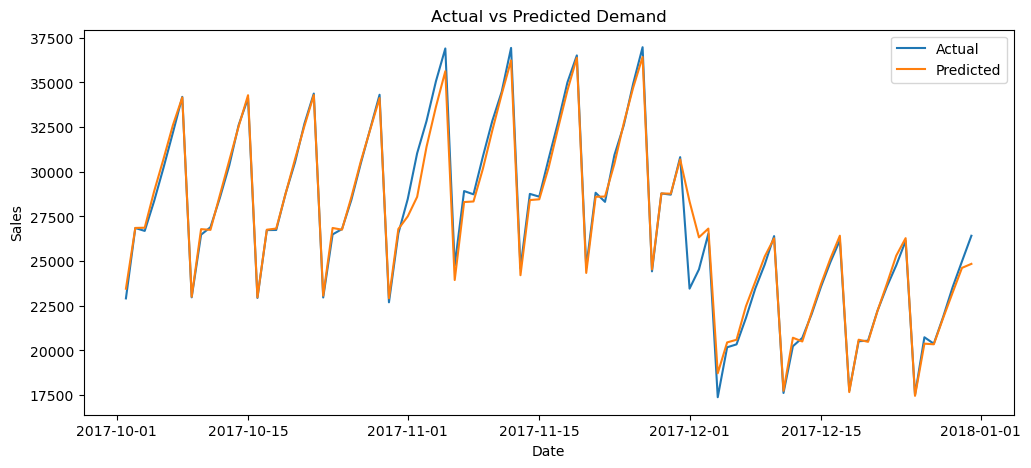

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    plot_daily.index,
    plot_daily["sales"],
    label="Actual"
)

plt.plot(
    plot_daily.index,
    plot_daily["predicted_sales"],
    label="Predicted"
)

plt.title(
    "Actual vs Predicted Demand"
)

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.show()

In [36]:
joblib.dump(
    forecast_model,
    "../models/demand_forecasting_model.pkl"
)

['../models/demand_forecasting_model.pkl']

In [37]:
forecast_results = pd.DataFrame({
    "Metric": [
        "Baseline MAE",
        "Baseline RMSE",
        "Model MAE",
        "Model RMSE"
    ],

    "Value": [
        baseline_mae,
        baseline_rmse,
        mae,
        rmse
    ]
})

forecast_results.to_csv(
    "../results/forecast_results.csv",
    index=False
)